# **Import Library**

This section loads all libraries required for data processing, modelling, evaluation, and visualisation.

- Import core, data manipulation, and plotting libraries.
- Import preprocessing, encoding, and imputation tools.
- Import machine learning models and evolutionary optimisation modules.
- Import evaluation metrics and statistical testing utilities.

In [1]:
import os
import shap
import time
import warnings
import random
import numpy as np
import pandas as pd
import scienceplots
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from adjustText import adjust_text
from plotly.subplots import make_subplots

from sklearn.impute import KNNImputer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from category_encoders import TargetEncoder, OneHotEncoder

import xgboost as xgb
from cmaes import CMA, CatCMAwM
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from art_resampling import ARTDataset, art_refresh_dataset_from_predictions
from evolutionary_boosting import run_evo_catcmawm, run_evo_cmaes, class_weights
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score, confusion_matrix

from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import mcnemar, cochrans_q, SquareTable

### **Global Config**

Sets the plotting style, random seeds for reproducibility, display options, and the main dataset parameters.

In [2]:
plt.style.use(["science", "no-latex"])

plt.rcParams.update({
    "font.size": 10,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 600
})

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [3]:
DATA_PATH        = "./RTA Dataset.csv"
TARGET_COL       = "Accident_severity"
CLASS_NAMES      = ["Fatal", "Serious", "Slight"]
NUM_CLASSES      = 3
TEST_SIZE        = 0.15   
VAL_SIZE         = 0.15   

### **Import Dataset**

Reads the accident dataset from the CSV file and displays its first rows.

In [4]:
df = pd.read_csv(DATA_PATH)
df.head()

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,Defect_of_vehicle,Area_accident_occured,Lanes_or_Medians,Road_allignment,Types_of_Junction,Road_surface_type,Road_surface_conditions,Light_conditions,Weather_conditions,Type_of_collision,Number_of_vehicles_involved,Number_of_casualties,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,No defect,Residential areas,NaN,Tangent road with flat terrain,No junction,Asphalt roads,Dry,Daylight,Normal,Collision with roadside-parked vehicles,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,No defect,Office areas,Undivided Two way,Tangent road with flat terrain,No junction,Asphalt roads,Dry,Daylight,Normal,Vehicle with vehicle collision,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,No defect,Recreational areas,other,NaN,No junction,Asphalt roads,Dry,Daylight,Normal,Collision with roadside objects,2,2,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,No defect,Office areas,other,Tangent road with mild grade and flat terrain,Y Shape,Earth roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,2,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,No defect,Industrial areas,other,Tangent road with flat terrain,Y Shape,Asphalt roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


# **Exploratory Data Analysis**

This section explores the dataset to understand its structure, quality, and main patterns.

- Inspect data types, unique values, missing values, duplicates, and summary statistics.
- Categorise columns by cardinality and numerical type.
- Visualise the target distribution and the relationships between accident characteristics.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Time                         12316 non-null  str  
 1   Day_of_week                  12316 non-null  str  
 2   Age_band_of_driver           12316 non-null  str  
 3   Sex_of_driver                12316 non-null  str  
 4   Educational_level            11575 non-null  str  
 5   Vehicle_driver_relation      11737 non-null  str  
 6   Driving_experience           11487 non-null  str  
 7   Type_of_vehicle              11366 non-null  str  
 8   Owner_of_vehicle             11834 non-null  str  
 9   Service_year_of_vehicle      8388 non-null   str  
 10  Defect_of_vehicle            7889 non-null   str  
 11  Area_accident_occured        12077 non-null  str  
 12  Lanes_or_Medians             11931 non-null  str  
 13  Road_allignment              12174 non-null  str  
 14  T

In [6]:
df.nunique()

Time                           1074
Day_of_week                       7
Age_band_of_driver                5
Sex_of_driver                     3
Educational_level                 7
Vehicle_driver_relation           4
Driving_experience                7
Type_of_vehicle                  17
Owner_of_vehicle                  4
Service_year_of_vehicle           6
Defect_of_vehicle                 3
Area_accident_occured            14
Lanes_or_Medians                  7
Road_allignment                   9
Types_of_Junction                 8
Road_surface_type                 5
Road_surface_conditions           4
Light_conditions                  4
Weather_conditions                9
Type_of_collision                10
Number_of_vehicles_involved       6
Number_of_casualties              8
Vehicle_movement                 13
Casualty_class                    4
Sex_of_casualty                   3
Age_band_of_casualty              6
Casualty_severity                 4
Work_of_casuality           

In [7]:
missing_pct = (df.isna().sum() / len(df) * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]
print(missing_pct)

Defect_of_vehicle         35.9451
Service_year_of_vehicle   31.8935
Work_of_casuality         25.9662
Fitness_of_casuality      21.3949
Type_of_vehicle            7.7135
Types_of_Junction          7.2020
Driving_experience         6.7311
Educational_level          6.0166
Vehicle_driver_relation    4.7012
Owner_of_vehicle           3.9136
Lanes_or_Medians           3.1260
Vehicle_movement           2.5008
Area_accident_occured      1.9406
Road_surface_type          1.3966
Type_of_collision          1.2585
Road_allignment            1.1530
dtype: float64


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,Number_of_vehicles_involved,Number_of_casualties
count,12316.0000,12316.0000
mean,2.0407,1.5481
std,0.6888,1.0072
min,1.0000,1.0000
25%,2.0000,1.0000
50%,2.0000,1.0000
75%,2.0000,2.0000
max,7.0000,8.0000


In [10]:
threshold = 5

high_cardinality_cols = [col for col in df.columns if df[col].dtype in ['str', 'category'] and df[col].nunique() > threshold]
low_cardinality_cols = [col for col in df.columns if df[col].dtype in ['str', 'category'] and df[col].nunique() <= threshold and col != TARGET_COL]
numerical_cols = [col for col in df.columns if df[col].dtype in ['int64', 'float64']]

print(f"High Cardinality Columns: {high_cardinality_cols}")
print(f"Low Cardinality Columns: {low_cardinality_cols}")
print(f"Numerical Columns: {numerical_cols}")

High Cardinality Columns: ['Time', 'Day_of_week', 'Educational_level', 'Driving_experience', 'Type_of_vehicle', 'Service_year_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians', 'Road_allignment', 'Types_of_Junction', 'Weather_conditions', 'Type_of_collision', 'Vehicle_movement', 'Age_band_of_casualty', 'Work_of_casuality', 'Pedestrian_movement', 'Cause_of_accident']
Low Cardinality Columns: ['Age_band_of_driver', 'Sex_of_driver', 'Vehicle_driver_relation', 'Owner_of_vehicle', 'Defect_of_vehicle', 'Road_surface_type', 'Road_surface_conditions', 'Light_conditions', 'Casualty_class', 'Sex_of_casualty', 'Casualty_severity', 'Fitness_of_casuality']
Numerical Columns: ['Number_of_vehicles_involved', 'Number_of_casualties']


### **Data Visualization**

Presents charts of the target class distribution, accident causes, casualties by day and education level, and accident severity by hour.

In [11]:
vc = df[TARGET_COL].value_counts()

plot_df = vc.reset_index()
plot_df.columns = [TARGET_COL, 'count']
plot_df['label'] = plot_df['count'].apply(lambda x: f'{x:,} ({x/len(df)*100:.1f}%)')

fig = px.bar(plot_df, x=TARGET_COL, y='count', color=TARGET_COL, text='label',
             title='Distribusi Kelas Target: Accident Severity', template='ggplot2')

fig.update_traces(textposition='outside')
fig.update_layout(width=1000, height=700, title={'x': 0.5, 'xanchor': 'center', 'font':{'size':20}}, xaxis_title="Accident Severty", yaxis_title='Frequency', showlegend=False)
fig.show()

In [12]:
fig = px.pie(df,df['Cause_of_accident'],df['Number_of_casualties'],color='Cause_of_accident',template='ggplot2',hole=0.35, title='Analisis Faktor  Penyebab Kecelakaan')
fig.update_layout(width=1200, height=800, title={'x': 0.5, 'xanchor': 'center', 'font':{'size':20}})

In [13]:
fig = px.histogram(df,df['Day_of_week'],df['Number_of_casualties'],color='Day_of_week',template='ggplot2', title='Jumlah Korban Kecelakaan Berdasarkan Hari')
fig.update_layout(width=1200, height=700, title={'x': 0.5, 'xanchor': 'center', 'font':{'size':20}})

In [14]:
fig = px.histogram(df,df['Educational_level'],df['Number_of_casualties'],color='Educational_level',template='ggplot2', title='Kecelakaan Berdasarkan Tingkat Pendidikan')
fig.update_layout(width=1200, height=700, title={'x': 0.5, 'xanchor': 'center', 'font':{'size':20}})

In [15]:
df['Time'] = pd.to_datetime(df['Time'], format='%H:%M:%S')
df['h'] = df['Time'].dt.hour

df_grouped = df.groupby(['h', 'Accident_severity']).size().reset_index(name='counts')
fig = px.line(
    df_grouped, x='h', y='counts',
    color='Accident_severity',
    markers=True,
    template='ggplot2',
    title='Trends Accident Severity'
)
fig.update_layout(
    xaxis_title='Hour of Day',
    yaxis_title='Number of Accidents',
    width=1200,
    height=600,
    xaxis=dict(dtick=1),
    title={'x': 0.5, 'xanchor': 'center', 'font': {'size': 20}},
    legend=dict(orientation='h', yanchor='top', y=-0.15, xanchor='center', x=0.5),
    legend_title_text=''
)
fig.show()

# **Data Preprocessing**

This section transforms the raw data into a clean, model-ready format.

- Encode the target labels and separate the features.
- Split the data into training, validation, and test sets.
- Encode categorical features, impute missing values, and scale the features.

In [16]:
label_map = {"Fatal injury": 0, "Serious Injury": 1, "Slight Injury": 2}
y = df[TARGET_COL].map(label_map).values
X = df.drop(columns=[TARGET_COL])

### **Data Splitting**

Encodes the target labels and divides the data into stratified training, validation, and test sets.

In [17]:
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=RANDOM_SEED)

print (f"Train set: {X_train.shape}, Validation set: {X_val.shape}, Test set: {X_test.shape}")

Train set: (8621, 32), Validation set: (1847, 32), Test set: (1848, 32)


### **Feature Encoding**

Applies target encoding to high-cardinality features and one-hot encoding to low-cardinality features, fitted on the training set only.

In [18]:
target_encoder = TargetEncoder(cols=high_cardinality_cols, smoothing=0.2, handle_missing='return_nan')

X_train[high_cardinality_cols] = target_encoder.fit_transform(X_train[high_cardinality_cols], y_train)
X_val[high_cardinality_cols] = target_encoder.transform(X_val[high_cardinality_cols])
X_test[high_cardinality_cols] = target_encoder.transform(X_test[high_cardinality_cols])

In [19]:
onehot_encoder = OneHotEncoder(cols=low_cardinality_cols, handle_missing='return_nan', use_cat_names=True)

X_train_encoded = onehot_encoder.fit_transform(X_train[low_cardinality_cols])
X_val_encoded = onehot_encoder.transform(X_val[low_cardinality_cols])
X_test_encoded = onehot_encoder.transform(X_test[low_cardinality_cols])

X_train_encoded = X_train.drop(columns=low_cardinality_cols).join(X_train_encoded)
X_val_encoded = X_val.drop(columns=low_cardinality_cols).join(X_val_encoded)
X_test_encoded = X_test.drop(columns=low_cardinality_cols).join(X_test_encoded)

### **Data Imputation**

Fills missing values using a distance-weighted K-Nearest Neighbors imputer fitted on the training set.

In [20]:
knn_imputer = KNNImputer(n_neighbors=5, weights="distance")

X_train = knn_imputer.fit_transform(X_train_encoded)
X_val = knn_imputer.transform(X_val_encoded)
X_test = knn_imputer.transform(X_test_encoded)

### **Feature Scaling**

Scales the features with a robust scaler fitted on the training set and restores them as data frames.

In [21]:
scaler = RobustScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [22]:
X_train = pd.DataFrame(X_train, columns=X_train_encoded.columns)
X_val = pd.DataFrame(X_val, columns=X_val_encoded.columns)
X_test = pd.DataFrame(X_test, columns=X_test_encoded.columns)

# **Modelling**

This section builds and trains the classification models used for comparison.

- Define a training routine with adaptive resampling.
- Configure baseline and evolutionary boosting models.
- Train all models and record predictions, training time, and inference time.

In [23]:
def train_model(model_builder, c_val=0.4, scheme="none"):
    model = model_builder()
    train_idx = np.arange(len(X_train))
    ds = ARTDataset(train_idx.reshape(-1, 1), np.asarray(y_train), c=c_val, cls_weights=np.full(NUM_CLASSES, 1.0 / NUM_CLASSES), seed=RANDOM_SEED, enable_art=True)
    for r in range(1, 5):
        sample_idx = ds.X[:, 0].astype(int)
        sw = class_weights(ds.y, scheme)
        fit_kwargs = {"sample_weight": sw} if sw is not None else {}
        model.fit(X_train.iloc[sample_idx], ds.y, **fit_kwargs)
        P_val = model.predict_proba(X_val)
        if r < 4:
            art_refresh_dataset_from_predictions(
                ds,
                np.asarray(y_val),
                P_val.argmax(1),
                NUM_CLASSES,
                {"batch_size": 256}
            )
    P_test = model.predict_proba(X_test)
    return model, P_val, P_test

In [24]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=100, random_state=RANDOM_SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12, random_state=RANDOM_SEED, n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=100, learning_rate=0.08, num_leaves=31, random_state=RANDOM_SEED, verbose=-1, n_jobs=-1),
    "CatBoost": CatBoostClassifier(iterations=100, learning_rate=0.08, depth=6, verbose=0, random_seed=RANDOM_SEED),
    "XGBoost": xgb.XGBClassifier(n_estimators=100, learning_rate=0.08, max_depth=6, enable_categorical=True, tree_method="hist", n_jobs=-1, random_state=RANDOM_SEED, verbosity=0),
    "Evolutionary Boost (CMA-ES)": None,
    "Evolutionary Boost (CatCMAwM)": None
}

In [25]:
test_probs = {}
test_preds = {}
trained_models = {}
train_times = {}
infer_times = {}

for name, model in models.items():
    t0 = time.time()
    if name == "Evolutionary Boost (CMA-ES)":
        best_cma, hist_cma = run_evo_cmaes(evo_budget=100, depths=[6, 8, 10], schemes=["none", "sqrt", "effective_number"], X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val, seed=RANDOM_SEED)
        m_evo = best_cma[5]
        train_times[name] = time.time() - t0
        t_inf = time.time()
        P_raw = m_evo.predict_proba(X_test)
        infer_times[name] = (time.time() - t_inf) / len(X_test) * 1000
        test_probs[name] = P_raw
        test_preds[name] = (P_raw * best_cma[3]).argmax(1)
        trained_models[name] = m_evo
    elif name == "Evolutionary Boost (CatCMAwM)":
        best_cat, hist_cat = run_evo_catcmawm(evo_budget=100, depths=[6, 8, 10], schemes=["none", "sqrt", "effective_number"], X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val, seed=RANDOM_SEED)
        m_evo = best_cat[5]
        train_times[name] = time.time() - t0
        t_inf = time.time()
        P_raw = m_evo.predict_proba(X_test)
        infer_times[name] = (time.time() - t_inf) / len(X_test) * 1000
        test_probs[name] = P_raw
        test_preds[name] = (P_raw * best_cat[3]).argmax(1)
        trained_models[name] = m_evo
    else:
        model, prob_val, prob_test = train_model(lambda: model)
        train_times[name] = time.time() - t0
        t_inf = time.time()
        prob_test = model.predict_proba(X_test)
        infer_times[name] = (time.time() - t_inf) / len(X_test) * 1000
        test_probs[name] = prob_test
        test_preds[name] = prob_test.argmax(1)
        trained_models[name] = model
    print(f"Training {name} Completed | {train_times[name]:.2f}s")


Training Logistic Regression Completed | 0.83s
Training Random Forest Completed | 1.03s
Training LightGBM Completed | 2.06s
Training CatBoost Completed | 2.31s
Training XGBoost Completed | 1.78s
Training Evolutionary Boost (CMA-ES) Completed | 324.06s
Training Evolutionary Boost (CatCMAwM) Completed | 274.94s


# **Evaluation**

This section measures the predictive performance of all trained models on the test set.

- Compute accuracy, precision, recall, F1, and balanced accuracy.
- Compile the results into a comparison table.

In [26]:
records = []

for name in test_preds:
    pred = test_preds[name]

    acc = accuracy_score(y_test, pred)
    b_acc = balanced_accuracy_score(y_test, pred)

    w_precision = precision_score(y_test, pred, average="weighted", zero_division=0)
    m_precision = precision_score(y_test, pred, average="macro", zero_division=0)

    w_recall = recall_score(y_test, pred, average="weighted", zero_division=0)
    m_recall = recall_score(y_test, pred, average="macro", zero_division=0)

    w_f1 = f1_score(y_test, pred, average="weighted", zero_division=0)
    m_f1 = f1_score(y_test, pred, average="macro", zero_division=0)

    precisions = precision_score(y_test, pred, average=None, labels=[0, 1, 2], zero_division=0)
    recalls = recall_score(y_test, pred, average=None, labels=[0, 1, 2], zero_division=0)
    f1s = f1_score(y_test, pred, average=None, labels=[0, 1, 2], zero_division=0)

    records.append({
        "Model": name,
        "Accuracy": acc,
        "Balanced_Acc": b_acc,
        "Precision_Macro": m_precision,
        "Precision_Weighted": w_precision,
        "Recall_Macro": m_recall,
        "Recall_Weighted": w_recall,
        "Macro_F1": m_f1,
        "Weighted_F1": w_f1,
        "Precision_Fatal": precisions[0],
        "Precision_Serious": precisions[1],
        "Precision_Slight": precisions[2],
        "Recall_Fatal": recalls[0],
        "Recall_Serious": recalls[1],
        "Recall_Slight": recalls[2],
        "F1_Fatal": f1s[0],
        "F1_Serious": f1s[1],
        "F1_Slight": f1s[2],
    })

comparison_df = pd.DataFrame(records).set_index("Model")
comparison_df.to_csv("outputs/model_comparison_results.csv", index=False)
comparison_df.round(4)

,Accuracy,Balanced_Acc,Precision_Macro,Precision_Weighted,Recall_Macro,Recall_Weighted,Macro_F1,Weighted_F1,Precision_Fatal,Precision_Serious,Precision_Slight,Recall_Fatal,Recall_Serious,Recall_Slight,F1_Fatal,F1_Serious,F1_Slight
Model,,,,,,,,,,,,,,,,,
Logistic Regression,0.6504,0.4399,0.3622,0.7556,0.4399,0.6504,0.3501,0.6966,0.0363,0.1891,0.8611,0.3913,0.1985,0.7300,0.0664,0.1937,0.7902
Random Forest,0.7895,0.4260,0.4842,0.7782,0.4260,0.7895,0.4437,0.7833,0.3000,0.2845,0.8680,0.1304,0.2595,0.8880,0.1818,0.2715,0.8779
LightGBM,0.7468,0.4795,0.4651,0.7805,0.4795,0.7468,0.4693,0.7617,0.2609,0.2590,0.8755,0.2609,0.3588,0.8189,0.2609,0.3008,0.8463
CatBoost,0.7100,0.4835,0.4046,0.7786,0.4835,0.7100,0.4184,0.7390,0.0854,0.2513,0.8772,0.3043,0.3740,0.7722,0.1333,0.3006,0.8214
XGBoost,0.7219,0.4951,0.4476,0.7730,0.4951,0.7219,0.4634,0.7439,0.2424,0.2281,0.8722,0.3478,0.3473,0.7901,0.2857,0.2753,0.8291
Evolutionary Boost (CMA-ES),0.6997,0.5413,0.4245,0.7937,0.5413,0.6997,0.3992,0.7397,0.0491,0.3444,0.8800,0.6087,0.2366,0.7786,0.0909,0.2805,0.8262
Evolutionary Boost (CatCMAwM),0.8074,0.5013,0.4834,0.7900,0.5013,0.8074,0.4852,0.7970,0.2286,0.3495,0.8722,0.3478,0.2481,0.9079,0.2759,0.2902,0.8897


### **Result Interpretations**

Visualises the metric comparison, model trade-offs, and confusion matrices to support interpretation of the results.

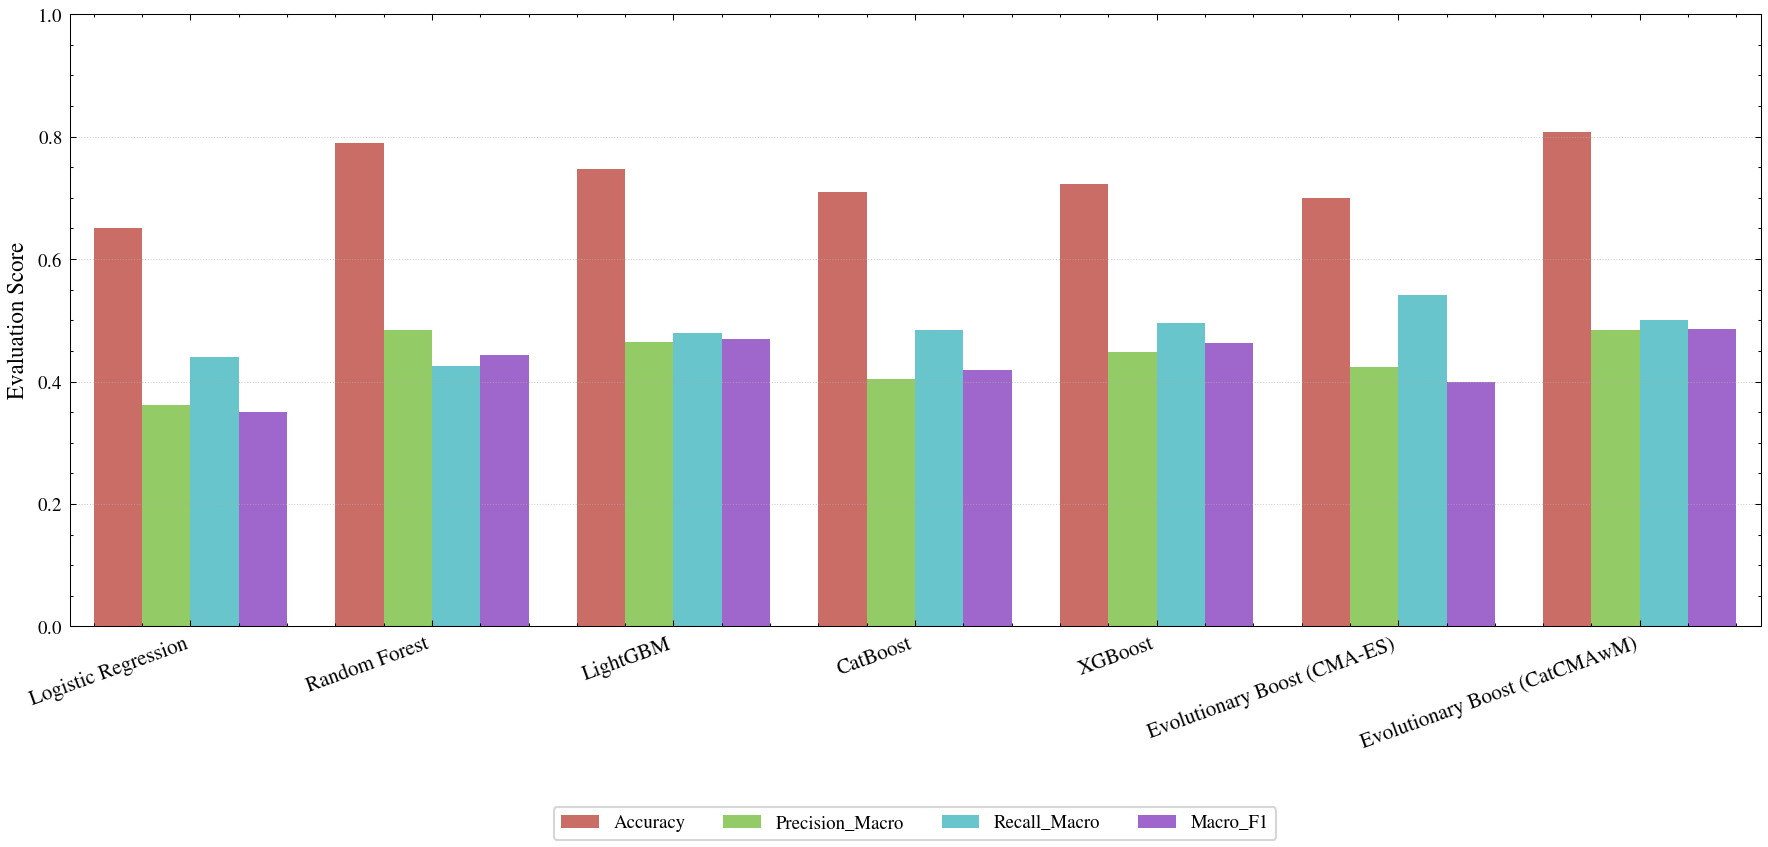

In [27]:
plt.figure(figsize=(12, 6))
plot_metrics = ["Accuracy", "Precision_Macro", "Recall_Macro", "Macro_F1"]
df_plot = comparison_df[plot_metrics].reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")

ax = sns.barplot(data=df_plot, x="Model", y="Score", hue="Metric", palette="hls")
plt.ylabel("Evaluation Score", fontsize=11)
plt.xlabel("", fontsize=11)
plt.ylim(0.0, 1.0)
plt.xticks(rotation=20, ha="right", fontsize=10)
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=4, frameon=True)
plt.tight_layout()
plt.show()

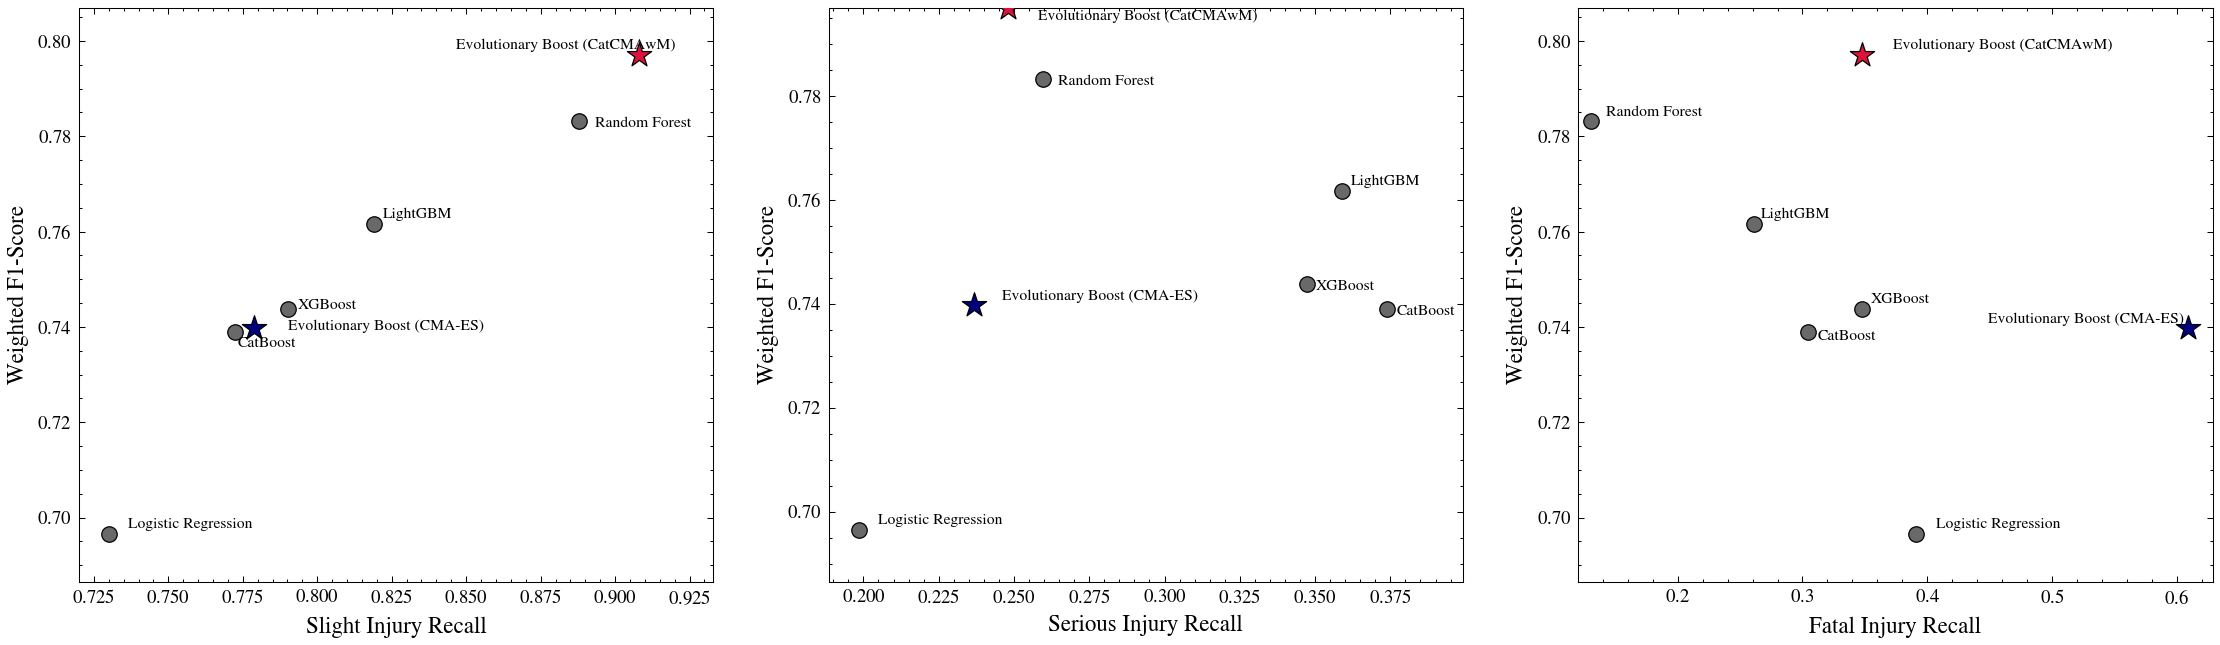

In [28]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.5))

texts1 = []
for name, row in comparison_df.iterrows():
    color = "crimson" if "CatCMAwM" in name else ("navy" if "CMA-ES" in name else "dimgray")
    marker = "*" if "CatCMAwM" in name or "CMA-ES" in name else "o"
    size = 150 if "CatCMAwM" in name or "CMA-ES" in name else 55
    ax1.scatter(row["Recall_Slight"], row["Weighted_F1"], color=color, s=size, marker=marker, edgecolors="black", linewidth=0.6, zorder=4)
    texts1.append(ax1.annotate(name, (row["Recall_Slight"], row["Weighted_F1"]), fontsize=7.5))

ax1.set_xlabel("Slight Injury Recall")
ax1.set_ylabel("Weighted F1-Score")
ax1.set_xlim(comparison_df["Recall_Slight"].min() - 0.01, comparison_df["Recall_Slight"].max() + 0.025)
ax1.set_ylim(comparison_df["Weighted_F1"].min() - 0.01, comparison_df["Weighted_F1"].max() + 0.01)
adjust_text(texts1, ax=ax1)


texts2 = []
for name, row in comparison_df.iterrows():
    color = "crimson" if "CatCMAwM" in name else ("navy" if "CMA-ES" in name else "dimgray")
    marker = "*" if "CatCMAwM" in name or "CMA-ES" in name else "o"
    size = 150 if "CatCMAwM" in name or "CMA-ES" in name else 55
    ax2.scatter(row["Recall_Serious"], row["Weighted_F1"], color=color, s=size, marker=marker, edgecolors="black", linewidth=0.6, zorder=4)
    texts2.append(ax2.annotate(name, (row["Recall_Serious"], row["Weighted_F1"]), fontsize=7.5))

ax2.set_xlabel("Serious Injury Recall")
ax2.set_ylabel("Weighted F1-Score")
ax2.set_xlim(comparison_df["Recall_Serious"].min() - 0.01, comparison_df["Recall_Serious"].max() + 0.025)
ax2.set_ylim(comparison_df["Weighted_F1"].min() - 0.01, comparison_df["Weighted_F1"].max() + 0.0)
adjust_text(texts2, ax=ax2)


texts3 = []
for name, row in comparison_df.iterrows():
    color = "crimson" if "CatCMAwM" in name else ("navy" if "CMA-ES" in name else "dimgray")
    marker = "*" if "CatCMAwM" in name or "CMA-ES" in name else "o"
    size = 150 if "CatCMAwM" in name or "CMA-ES" in name else 55
    ax3.scatter(row["Recall_Fatal"], row["Weighted_F1"], color=color, s=size, marker=marker, edgecolors="black", linewidth=0.6, zorder=4)
    texts3.append(ax3.annotate(name,(row["Recall_Fatal"], row["Weighted_F1"]),fontsize=7.5))

ax3.set_xlabel("Fatal Injury Recall")
ax3.set_ylabel("Weighted F1-Score")
ax3.set_xlim(comparison_df["Recall_Fatal"].min() - 0.01, comparison_df["Recall_Fatal"].max() + 0.02)
ax3.set_ylim(comparison_df["Weighted_F1"].min() - 0.01, comparison_df["Weighted_F1"].max() + 0.01)
adjust_text(texts3, ax=ax3)
plt.tight_layout(w_pad=2)
plt.show()

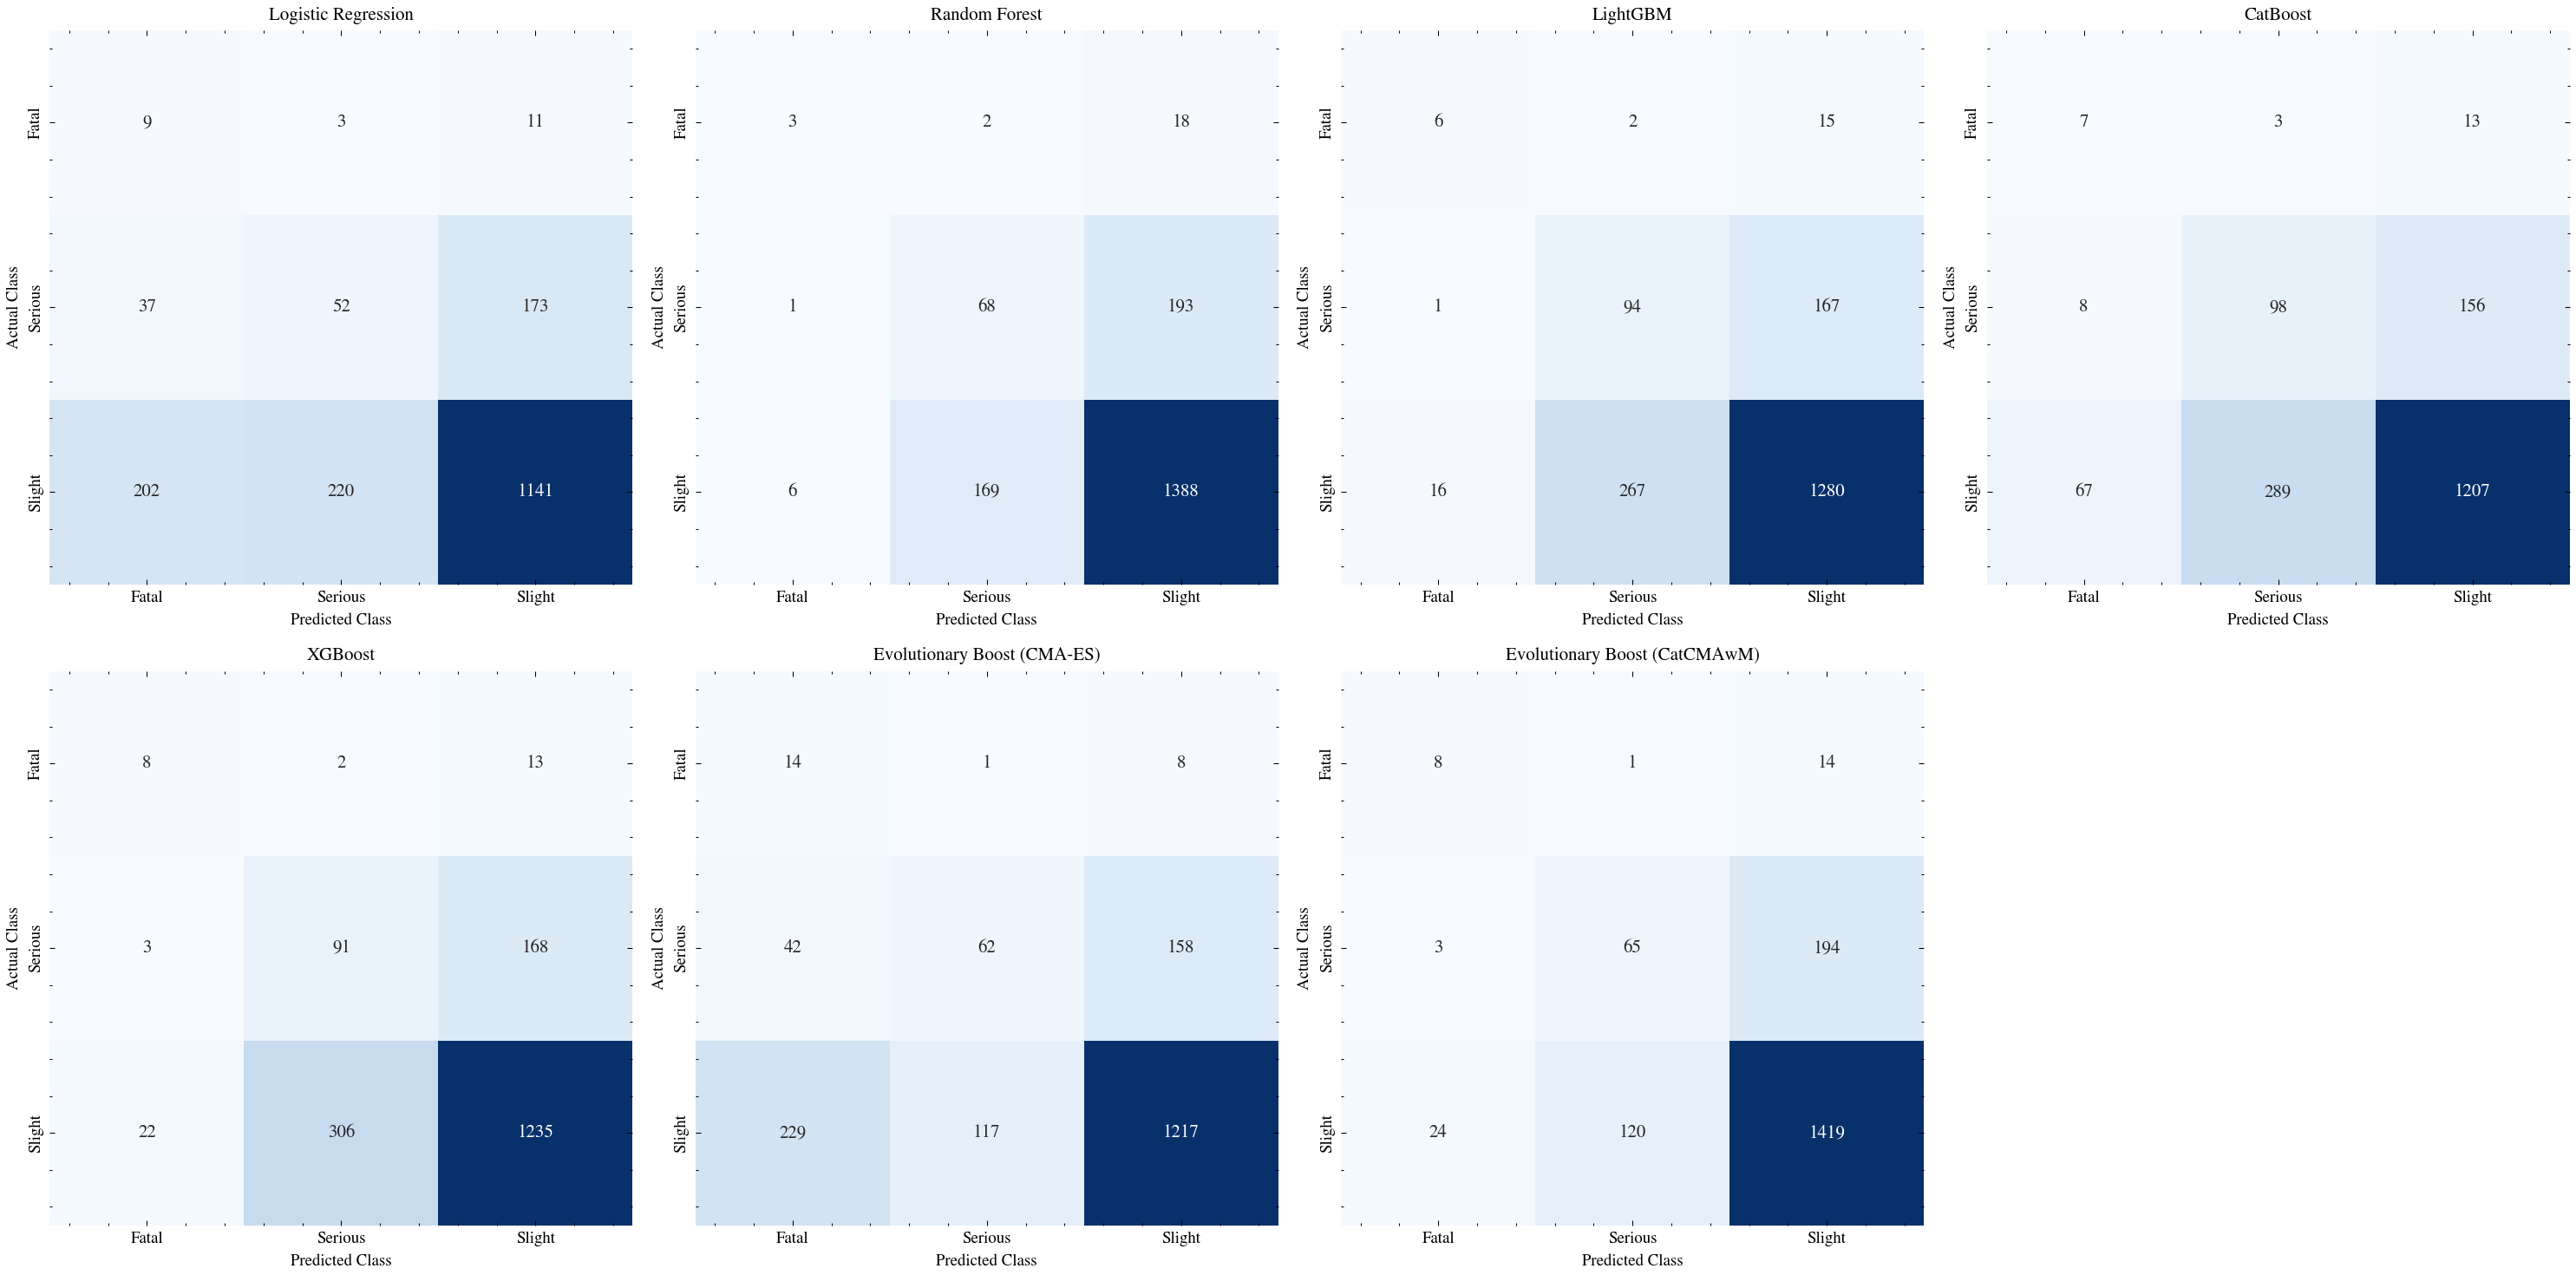

In [29]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

model_list = list(test_preds.keys())
for i, name in enumerate(model_list):
    cm = confusion_matrix(y_test, test_preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    axes[i].set_title(f"{name}", fontsize=10)
    axes[i].set_xlabel("Predicted Class", fontsize=9)
    axes[i].set_ylabel("Actual Class", fontsize=9)

fig.delaxes(axes[7])
plt.tight_layout()
plt.show()

# **Feature Importance**

This section explains which features drive the predictions of the evolutionary boosting models.

- Compute SHAP values on a sample of the test set.
- Visualise and compare the feature contributions of each model.

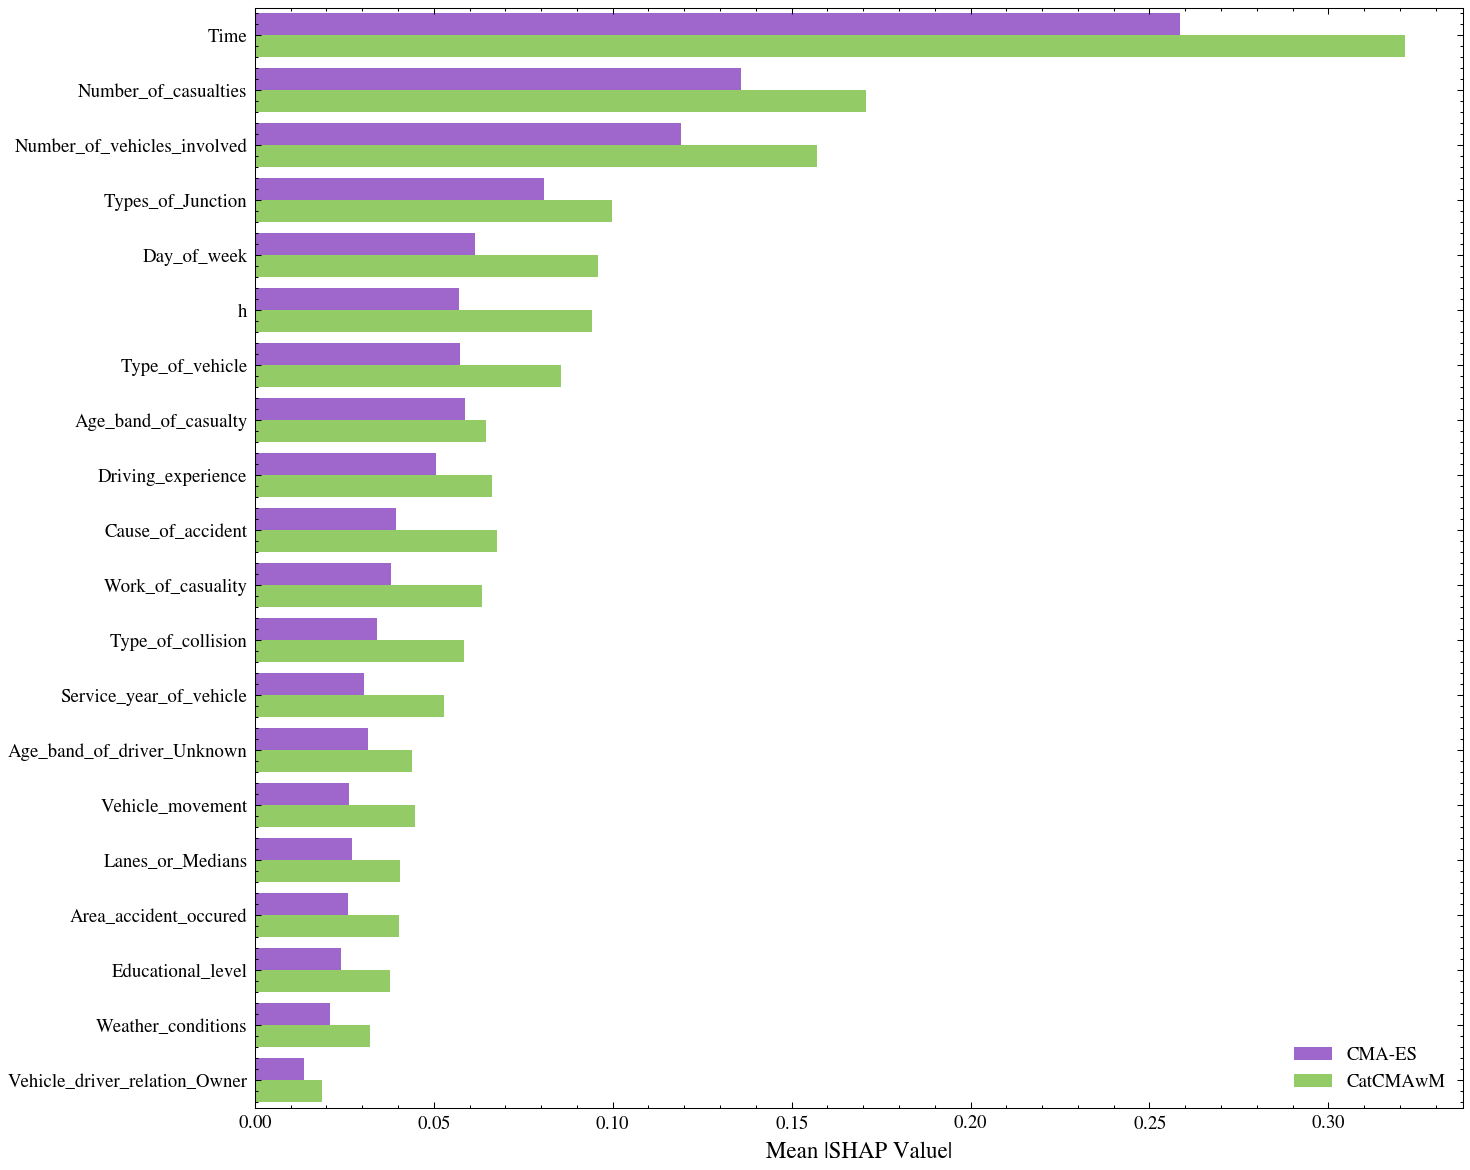

In [30]:
models = {
    "CMA-ES": trained_models["Evolutionary Boost (CMA-ES)"],
    "CatCMAwM": trained_models["Evolutionary Boost (CatCMAwM)"]
}

X_shap = X_test.sample(n=min(1000, len(X_test)), random_state=42)
records = []

for name, model in models.items():
    sv = shap.TreeExplainer(model)(X_shap).values
    importance = np.abs(sv).mean(axis=(0, 2)) if sv.ndim == 3 else np.abs(sv).mean(axis=0)
    records.extend(zip(X_shap.columns, importance, [name] * len(importance)))

shap_df = pd.DataFrame(records, columns=["Feature", "Mean |SHAP|", "Model"])
top = shap_df.groupby("Feature")["Mean |SHAP|"].mean().nlargest(20).index
palette = sns.color_palette("hls", 8)
colors = [palette[6], palette[2]]
plt.figure(figsize=(10, 8))
sns.barplot(data=shap_df[shap_df["Feature"].isin(top)], y="Feature", x="Mean |SHAP|", hue="Model", palette=colors, order=top, orient="h")
plt.xlabel("Mean |SHAP Value|", fontsize=11)
plt.ylabel("")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

# **Ablation Study**

This section evaluates the contribution of each component of the proposed method.

- Define a metric function for ablation variants.
- Compare the variants using the validation and test results.
- Visualise the performance differences.

In [31]:
def compute_metrics(y_true, pred):
    rec = recall_score(y_true, pred, average=None, zero_division=0)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Balanced_Acc": balanced_accuracy_score(y_true, pred),
        "Weighted_F1": f1_score(y_true, pred, average="weighted"),
        "Macro_F1": f1_score(y_true, pred, average="macro"),
        "Recall_Fatal": rec[0],
        "Recall_Serious": rec[1],
        "Recall_Slight": rec[2]
    }

ablation_dict = {}

m_base = xgb.XGBClassifier(n_estimators=100, learning_rate=0.08, max_depth=6, random_state=RANDOM_SEED, verbosity=0)
m_base.fit(X_train, y_train)
ablation_dict["Base XGBoost"] = compute_metrics(y_test, m_base.predict(X_test))

m_w = xgb.XGBClassifier(n_estimators=100, learning_rate=0.08, max_depth=6, random_state=RANDOM_SEED, verbosity=0)
m_w.fit(X_train, y_train, sample_weight=class_weights(y_train, "sqrt"))
ablation_dict["XGBoost + Weighting"] = compute_metrics(y_test, m_w.predict(X_test))

# m_art, _, P_art = train_model(lambda: xgb.XGBClassifier(n_estimators=100, learning_rate=0.08, max_depth=6, random_state=RANDOM_SEED, verbosity=0), c_val=0.4, scheme="none")
# ablation_dict["XGBoost + ART"] = compute_metrics(y_test, P_art.argmax(1))

ablation_dict["Evoltionary Boost (CMA-ES)"] = compute_metrics(y_test, test_preds["Evolutionary Boost (CMA-ES)"])
ablation_dict["Evolutionary Boost (CatCMAwM)"] = compute_metrics(y_test, test_preds["Evolutionary Boost (CatCMAwM)"])

ablation_df = pd.DataFrame(ablation_dict).T
ablation_df.to_csv("outputs/ablation_study.csv", index=False)
ablation_df.round(4)

,Accuracy,Balanced_Acc,Weighted_F1,Macro_F1,Recall_Fatal,Recall_Serious,Recall_Slight
Base XGBoost,0.8512,0.3635,0.7915,0.3652,0.0435,0.0496,0.9974
XGBoost + Weighting,0.8382,0.4547,0.8107,0.4746,0.2174,0.1908,0.9559
Evoltionary Boost (CMA-ES),0.6997,0.5413,0.7397,0.3992,0.6087,0.2366,0.7786
Evolutionary Boost (CatCMAwM),0.8074,0.5013,0.7970,0.4852,0.3478,0.2481,0.9079


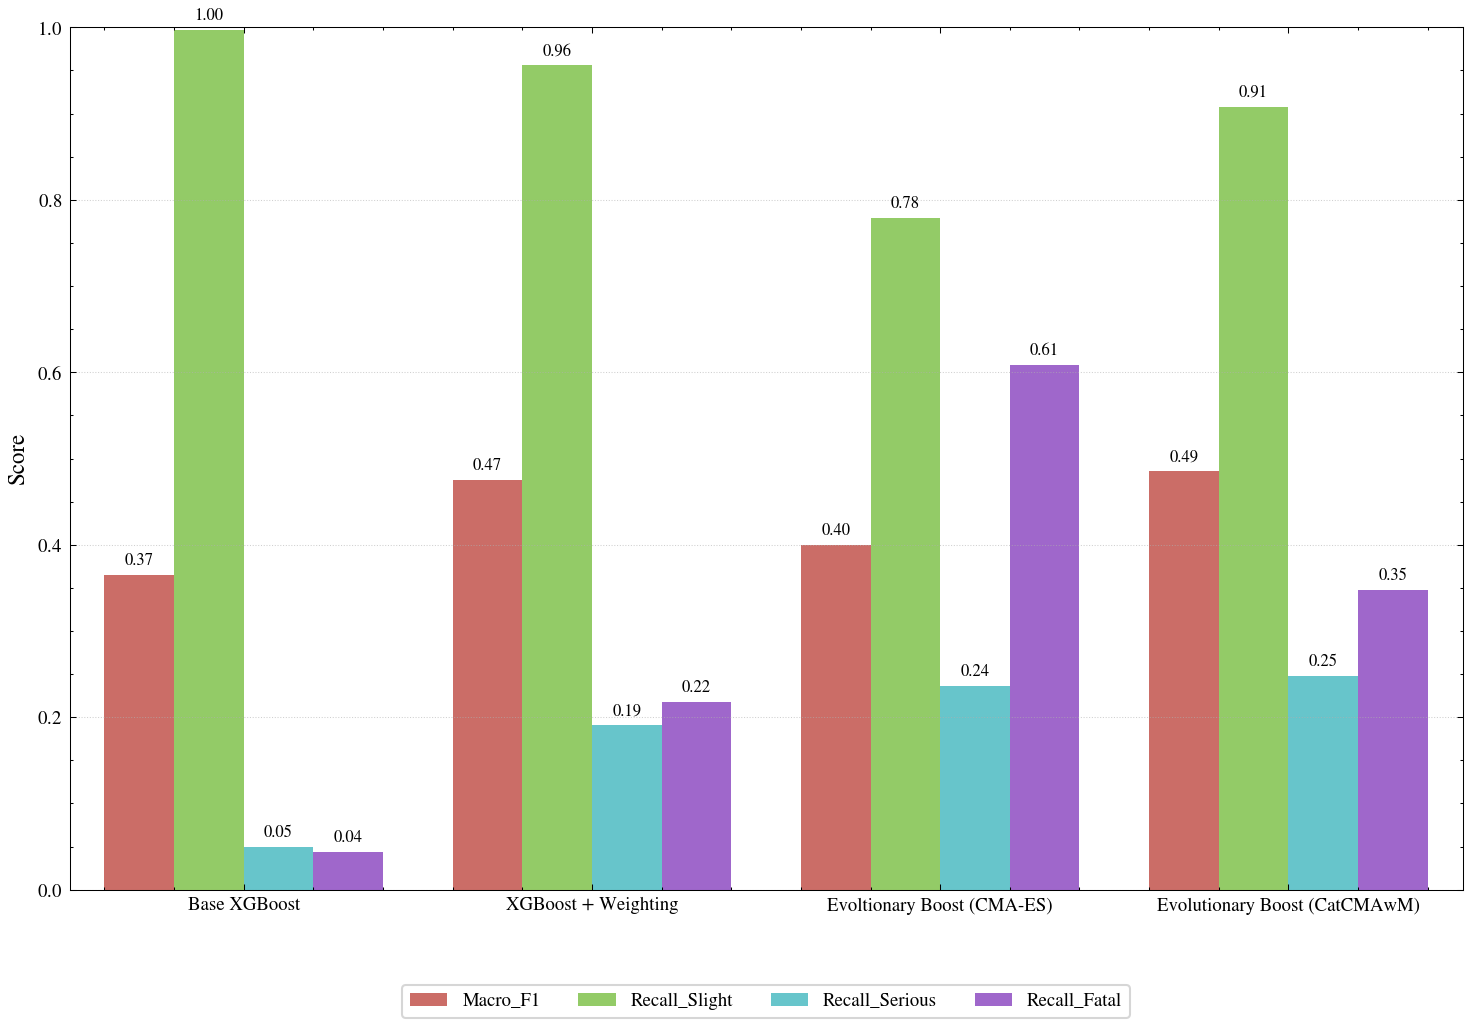

In [32]:
import scienceplots
plt.style.use(["science", "no-latex"])

fig, ax = plt.subplots(figsize=(10, 7))
df_ab_plot = ablation_df[["Macro_F1", "Recall_Slight", "Recall_Serious", "Recall_Fatal"]].reset_index().melt(id_vars="index", var_name="Metric", value_name="Score")
sns.barplot(data=df_ab_plot, x="index", y="Score", hue="Metric", palette="hls", ax=ax)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", padding=3, fontsize=8)
ax.set(xlabel="", ylabel="Score", ylim=(0, 1))
plt.xticks(rotation=0, ha="center", fontsize=9)
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.legend(loc="upper center", fontsize=9, bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=True)
plt.tight_layout()
plt.show()

# **Statistical Significance Testing**

This section tests whether the performance differences between models are statistically significant.

- Apply Cochran's Q test across all models.
- Apply pairwise McNemar, Stuart-Maxwell, and permutation tests against the proposed model.
- Use bootstrap resampling and multiple-testing correction.

In [33]:
n_bootstraps = 1000
stat_records = []
target_model = "Evolutionary Boost (CatCMAwM)"
pred_target = test_preds[target_model]
boot_indices = [np.random.choice(len(y_test), size=len(y_test), replace=True) for _ in range(n_bootstraps)]

# Uji 1 (omnibus): Cochran's Q
correct = np.column_stack([(p == y_test).astype(int) for p in test_preds.values()])
q = cochrans_q(correct)
print(f"Cochran's Q = {q.statistic:.4f}, df = {q.df}, p = {q.pvalue:.4g}")

# uji permutasi berpasangan
def macro_f1_diff(a, b):         
    return f1_score(y_test, a, average="macro") - f1_score(y_test, b, average="macro")

for name in test_preds:
    if name == target_model:
        continue
    pred_other = test_preds[name]

    c1 = (pred_target == y_test)
    c2 = (pred_other == y_test)
    # Uji 2: McNemar exact (binomial), menggantikan chi-kuadrat manual
    p_mcnemar = mcnemar(pd.crosstab(c1, c2).reindex(index=[True, False], columns=[True, False], fill_value=0).values,
                        exact=True).pvalue
    # Uji 3: Stuart-Maxwell (homogenitas marginal): apakah sebaran kelas prediksi kedua model berbeda
    try:
        p_sm = SquareTable(pd.crosstab(pred_target, pred_other).reindex(
            index=np.unique(y_test), columns=np.unique(y_test), fill_value=0).values + 0.5).homogeneity().pvalue
    except Exception:
        p_sm = np.nan
    # Uji 4: permutasi berpasangan pada selisih Macro-F1 (scipy)
    perm = stats.permutation_test((pred_target, pred_other), macro_f1_diff, permutation_type="samples",
                                  vectorized=False, n_resamples=1000, random_state=RANDOM_SEED)

    # Uji 5: bootstrap (kode asli; Macro-F1 ditambahkan)
    diff_bacc, diff_wf1, diff_mf1 = [], [], []
    for idx in boot_indices:
        yb = y_test[idx]
        diff_bacc.append(balanced_accuracy_score(yb, pred_target[idx]) - balanced_accuracy_score(yb, pred_other[idx]))
        diff_wf1.append(f1_score(yb, pred_target[idx], average="weighted") - f1_score(yb, pred_other[idx], average="weighted"))
        diff_mf1.append(f1_score(yb, pred_target[idx], average="macro") - f1_score(yb, pred_other[idx], average="macro"))

    ci_bacc = np.percentile(diff_bacc, [2.5, 97.5])
    ci_wf1 = np.percentile(diff_wf1, [2.5, 97.5])
    ci_mf1 = np.percentile(diff_mf1, [2.5, 97.5])

    stat_records.append({
        "Comparison": f"CatCMAwM vs {name}",
        "McNemar_p": p_mcnemar,
        "StuartMaxwell_p": p_sm,
        "Perm_MacroF1_p": perm.pvalue,
        "Delta_Macro_F1": np.mean(diff_mf1),
        "MF1_95CI": f"[{ci_mf1[0]:.4f}, {ci_mf1[1]:.4f}]",
        "Delta_Balanced_Acc": np.mean(diff_bacc),
        "BAcc_95CI": f"[{ci_bacc[0]:.4f}, {ci_bacc[1]:.4f}]",
        "Delta_Weighted_F1": np.mean(diff_wf1),
        "WF1_95CI": f"[{ci_wf1[0]:.4f}, {ci_wf1[1]:.4f}]",
    })

stat_df = pd.DataFrame(stat_records).set_index("Comparison")
for col in ["McNemar_p", "StuartMaxwell_p", "Perm_MacroF1_p"]:
    stat_df[col + "_holm"] = multipletests(stat_df[col].fillna(1.0), method="holm")[1]
stat_df["Significant (Holm p<0.05)"] = stat_df[["McNemar_p_holm", "Perm_MacroF1_p_holm"]].min(axis=1) < 0.05
stat_df.to_csv("outputs/statistical_test.csv")  
stat_df.round(4)

Cochran's Q = 371.2063, df = 6, p = 4.309e-77


,McNemar_p,StuartMaxwell_p,Perm_MacroF1_p,Delta_Macro_F1,MF1_95CI,Delta_Balanced_Acc,BAcc_95CI,Delta_Weighted_F1,WF1_95CI,McNemar_p_holm,StuartMaxwell_p_holm,Perm_MacroF1_p_holm,Significant (Holm p<0.05)
Comparison,,,,,,,,,,,,,
CatCMAwM vs Logistic Regression,0.0000,0.0000,0.0020,0.1341,"[0.0878, 0.1828]",0.0610,"[-0.0049, 0.1326]",0.1010,"[0.0845, 0.1186]",0.0000,0.0000,0.0120,True
CatCMAwM vs Random Forest,0.0296,0.0000,0.2018,0.0408,"[-0.0174, 0.1013]",0.0741,"[0.0207, 0.1359]",0.0137,"[0.0009, 0.0270]",0.0296,0.0000,0.4036,True
CatCMAwM vs LightGBM,0.0000,0.0000,0.4316,0.0157,"[-0.0222, 0.0568]",0.0212,"[-0.0158, 0.0666]",0.0356,"[0.0210, 0.0500]",0.0000,0.0000,0.4316,True
CatCMAwM vs CatBoost,0.0000,0.0000,0.0020,0.0653,"[0.0297, 0.1028]",0.0163,"[-0.0316, 0.0674]",0.0583,"[0.0427, 0.0732]",0.0000,0.0000,0.0120,True
CatCMAwM vs XGBoost,0.0000,0.0000,0.0739,0.0214,"[-0.0035, 0.0456]",0.0061,"[-0.0109, 0.0235]",0.0533,"[0.0390, 0.0678]",0.0000,0.0000,0.2218,True
CatCMAwM vs Evolutionary Boost (CMA-ES),0.0000,0.0000,0.0020,0.0845,"[0.0435, 0.1297]",-0.0403,"[-0.1107, 0.0200]",0.0573,"[0.0438, 0.0708]",0.0000,0.0000,0.0120,True


# **Cost and Computational Efficiency Evaluation**

This section assesses the practical cost and computational efficiency of the models.

- Calculate misclassification cost using a cost matrix.
- Compare the proposed optimisation with random search under an equal budget.
- Report training time, inference latency, and throughput.

In [34]:
cost_matrix = np.array([
    [0.0, 4.0, 10.0],
    [1.0, 0.0, 5.0],
    [1.0, 1.0, 0.0]
])

cost_records = []
for name in test_preds:
    pred = test_preds[name]
    sample_costs = cost_matrix[y_test, pred]
    cost_records.append({
        "Model": name,
        "Mean_Misclassification_Cost": float(np.mean(sample_costs)),
        "Total_Cost": float(np.sum(sample_costs)),
        "Cost_Reduction_vs_Default_XGB (%)": 0.0
    })

cost_df = pd.DataFrame(cost_records).set_index("Model")
base_cost = cost_df.loc["XGBoost", "Total_Cost"]
cost_df["Cost_Reduction_vs_Default_XGB (%)"] = ((base_cost - cost_df["Total_Cost"]) / base_cost * 100.0)
cost_df.to_csv("outputs/cost.csv", index=False)
cost_df.round(4)

,Mean_Misclassification_Cost,Total_Cost,Cost_Reduction_vs_Default_XGB (%)
Model,,,
Logistic Regression,0.7825,1446.0000,-10.4660
Random Forest,0.7192,1329.0000,-1.5279
LightGBM,0.6910,1277.0000,2.4446
CatBoost,0.6959,1286.0000,1.7571
XGBoost,0.7083,1309.0000,0.0000
Evolutionary Boost (CMA-ES),0.6829,1262.0000,3.5905
Evolutionary Boost (CatCMAwM),0.6824,1261.0000,3.6669


In [35]:
equal_budget = 100

rs_scores = []
np.random.seed(RANDOM_SEED)
for _ in range(equal_budget):
    lr = float(np.exp(np.log(0.03) + np.random.rand() * (np.log(0.15) - np.log(0.03))))
    d = int(np.random.choice([6, 8, 10]))
    c_val = 0.25 + 0.45 * np.random.rand()
    sch = str(np.random.choice(["none", "sqrt", "effective_number"]))
    sf = 1.0 + 3.0 * np.random.rand()
    ss = 1.0 + 1.5 * np.random.rand()
    scales = np.array([sf, ss, 1.0])
    
    ds = ARTDataset(np.arange(len(X_train)).reshape(-1, 1), y_train, c=c_val, cls_weights=np.full(3, 1/3), seed=RANDOM_SEED, enable_art=True)
    m = xgb.XGBClassifier(n_estimators=100, learning_rate=lr, max_depth=d, subsample=0.8, colsample_bytree=0.8, enable_categorical=True, tree_method="hist", n_jobs=-1, random_state=RANDOM_SEED, verbosity=0)
    for r in range(1, 4):
        s_idx = ds.X[:, 0].astype(int)
        sw = class_weights(ds.y, sch)
        m.fit(X_train.iloc[s_idx], ds.y, sample_weight=sw)
        pv = m.predict_proba(X_val)
        if r < 3:
            art_refresh_dataset_from_predictions(ds, y_val, pv.argmax(1), 3, {"batch_size": 256})
    pred_v = (pv * scales).argmax(1)
    wf1 = f1_score(y_val, pred_v, average="weighted")
    rec = recall_score(y_val, pred_v, average=None, zero_division=0)
    fit = wf1 * (1.0 + 0.6 * rec[0] + 0.3 * rec[1])
    if wf1 < 0.72:
        fit -= (0.72 - wf1) * 4.0
    rs_scores.append(fit)

cma_res, cma_hist = run_evo_cmaes(evo_budget=equal_budget, depths=[6, 8, 10], schemes=["none", "sqrt", "effective_number"], X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val, seed=RANDOM_SEED)
cat_res, cat_hist = run_evo_catcmawm(evo_budget=equal_budget, depths=[6, 8, 10], schemes=["none", "sqrt", "effective_number"], X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val, seed=RANDOM_SEED)

rs_best = np.maximum.accumulate(rs_scores)
budget_comparison_df = pd.DataFrame({
    "Optimization_Method": ["Random Search", "Continuous CMA-ES", "CatCMAwM"],
    "Search_Space_Type": ["Random Uniform", "Continuous Relaxation", "Mixed-Space Margin (CatCMAwM)"],
    "Evaluations": [equal_budget, equal_budget, equal_budget],
    "Best_Validation_Fitness": [float(rs_best[-1]), float(cma_res[0]), float(cat_res[0])],
    "Relative_Gain_vs_Random (%)": [0.0, (float(cma_res[0]) - float(rs_best[-1])) / abs(float(rs_best[-1])) * 100, (float(cat_res[0]) - float(rs_best[-1])) / abs(float(rs_best[-1])) * 100]
}).set_index("Optimization_Method")
budget_comparison_df.to_csv("budget_comparison.csv", index=False)
budget_comparison_df.round(4)

,Search_Space_Type,Evaluations,Best_Validation_Fitness,Relative_Gain_vs_Random (%)
Optimization_Method,,,,
Random Search,Random Uniform,100,1.1348,0.0000
Continuous CMA-ES,Continuous Relaxation,100,1.1735,3.4080
CatCMAwM,Mixed-Space Margin (CatCMAwM),100,1.1228,-1.0564


In [36]:
perf_records = []
for name in test_preds:
    perf_records.append({
        "Model": name,
        "Training_Time (s)": train_times.get(name, 0.0),
        "Inference_Latency (ms/sample)": infer_times.get(name, 0.0),
        "Throughput (samples/s)": 1000.0 / max(infer_times.get(name, 1.0), 1e-4),
        "Weighted F1": comparison_df.loc[name, "Weighted_F1"],
        "Macro F1": comparison_df.loc[name, "Macro_F1"]
    })

perf_df = pd.DataFrame(perf_records).set_index("Model")
perf_df.to_csv("outputs/performance.csv", index=False)
perf_df.round(4)

,Training_Time (s),Inference_Latency (ms/sample),Throughput (samples/s),Weighted F1,Macro F1
Model,,,,,
Logistic Regression,0.8285,0.0005,2016408.3746,0.6966,0.3501
Random Forest,1.0283,0.0149,66939.6313,0.7833,0.4437
LightGBM,2.0622,0.0030,336024.3548,0.7617,0.4693
CatBoost,2.3089,0.0013,784045.4979,0.7390,0.4184
XGBoost,1.7806,0.0030,338637.5024,0.7439,0.4634
Evolutionary Boost (CMA-ES),324.0608,0.0046,215727.0746,0.7397,0.3992
Evolutionary Boost (CatCMAwM),274.9447,0.0046,218765.3126,0.7970,0.4852
